# 01 · AI4I 2020 — Exploratory Data Analysis

**Goal:** understand the sensor readings, the failure target and its subtypes, and pick
preprocessing that avoids leakage.

The dataset is **synthetic**: UCI describes how each variable and failure mode was generated.
That matters for interpreting results (see §8). EDA here runs on all 10,000 rows because it
is descriptive. No preprocessing parameter is fit on the data at this stage, and the
engineered features are fixed physical formulas, so nothing from the hold-out set reaches a
model.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as C
from src import visualization as V
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
FIG = C.FIGURES_DIR
from src.data_loader import load_ai4i
from src.feature_engineering import AI4IFeatureEngineer
df = load_ai4i()
FIGD = FIG / 'ai4i'

## 1. Dimensions, columns and data types

In [2]:
print("shape:", df.shape)
desc = {
 "UDI": "Unique row identifier 1..10000 (dropped: no signal)",
 "Product ID": "Quality letter + serial number (dropped: identifier)",
 "Type": "Product quality variant L / M / H (50/30/20% by design)",
 "Air temperature [K]": "Random walk, sd 2 K around 300 K",
 "Process temperature [K]": "Air temperature + 10 K + random walk (sd 1 K)",
 "Rotational speed [rpm]": "From 2860 W power + normal noise",
 "Torque [Nm]": "Normal around 40 Nm, sd 10, no negatives",
 "Tool wear [min]": "Increases by 5/3/2 min per process for H/M/L",
 "Machine failure": "TARGET: 1 if any failure mode occurred",
 "TWF": "Tool wear failure (subtype, LEAKAGE: excluded from inputs)",
 "HDF": "Heat dissipation failure (subtype, excluded)",
 "PWF": "Power failure (subtype, excluded)",
 "OSF": "Overstrain failure (subtype, excluded)",
 "RNF": "Random failure, 0.1% chance (subtype, excluded)",
}
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "description": pd.Series(desc)}))

shape: (10000, 14)


,dtype,n_unique,description
UDI,int64,10000,Unique row identifier 1..10000 (dropped: no si...
Product ID,str,10000,Quality letter + serial number (dropped: ident...
Type,str,3,Product quality variant L / M / H (50/30/20% b...
Air temperature [K],float64,93,"Random walk, sd 2 K around 300 K"
Process temperature [K],float64,82,Air temperature + 10 K + random walk (sd 1 K)
Rotational speed [rpm],int64,941,From 2860 W power + normal noise
Torque [Nm],float64,577,"Normal around 40 Nm, sd 10, no negatives"
Tool wear [min],int64,246,Increases by 5/3/2 min per process for H/M/L
Machine failure,int64,2,TARGET: 1 if any failure mode occurred
TWF,int64,2,"Tool wear failure (subtype, LEAKAGE: excluded ..."


## 2. Missing values and duplicates

In [3]:
print("missing cells:", int(df.isna().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()), "| duplicate Product IDs:", int(df['Product ID'].duplicated().sum()))
print("duplicate rows ignoring identifiers:", int(df.drop(columns=C.AI4I_ID_COLS).duplicated().sum()))

missing cells: 0
duplicate rows: 0 | duplicate Product IDs: 0
duplicate rows ignoring identifiers: 0


## 3. Statistical summary

In [4]:
display(df[C.AI4I_NUMERIC].describe().T.round(2))
display(df.groupby(C.AI4I_TARGET)[C.AI4I_NUMERIC].mean().T.round(2).rename(columns={0:'mean | no failure',1:'mean | failure'}))

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0


Machine failure,mean | no failure,mean | failure
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


## 4. Target distribution, class imbalance and failure subtypes

failure rate 3.39%; imbalance ratio 28.5 : 1


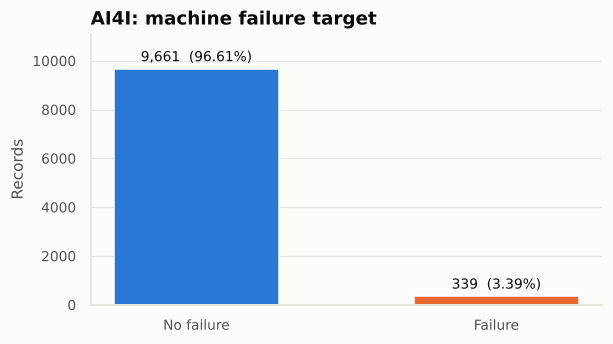

,count,share_of_failures
TWF,46,0.136
HDF,115,0.339
PWF,95,0.280
OSF,98,0.289
RNF,19,0.056


,"failure=1, no subtype","subtype=1, failure=0",rows with >1 subtype
0,9,18,24


,TWF,HDF,PWF,OSF,RNF
subtype flags on failure=0 rows,0,0,0,0,18


In [5]:
y = df[C.AI4I_TARGET]
print(f"failure rate {y.mean():.2%}; imbalance ratio {(y==0).sum()/(y==1).sum():.1f} : 1")
V.save(V.target_distribution(y, "AI4I: machine failure target"), FIGD / "01_target_distribution.png"); plt.show()
sub = C.AI4I_LEAKAGE_COLS
display(df[sub].sum().rename("count").to_frame().assign(share_of_failures=lambda d: (d['count']/y.sum()).round(3)))
anysub = df[sub].any(axis=1)
incons = pd.DataFrame({
  "failure=1, no subtype": [int(((y==1)&~anysub).sum())],
  "subtype=1, failure=0": [int(((y==0)&anysub).sum())],
  "rows with >1 subtype": [int((df[sub].sum(axis=1)>1).sum())]})
display(incons)
display(df.loc[(y==0)&anysub, sub].sum().rename("subtype flags on failure=0 rows").to_frame().T)

## 5. Product type vs failure

,records,failures,failure_rate
Type,,,
L,6000,235,3.92%
M,2997,83,2.77%
H,1003,21,2.09%


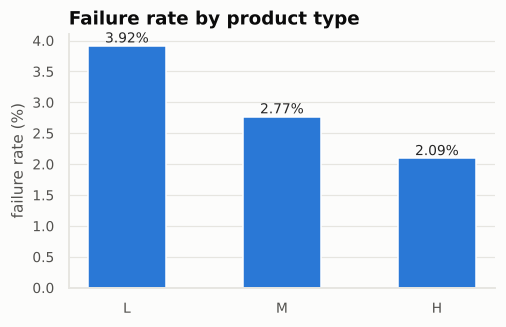

In [6]:
ct = df.groupby("Type")[C.AI4I_TARGET].agg(records="size", failures="sum", failure_rate="mean").loc[["L","M","H"]]
display(ct.assign(failure_rate=lambda d: (d.failure_rate*100).round(2).astype(str)+"%"))
fig, ax = plt.subplots(figsize=(5,3)); ax.bar(ct.index, ct.failure_rate*100, color=V.SERIES[0], width=0.5)
for i,v in enumerate(ct.failure_rate*100): ax.text(i, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("failure rate (%)"); ax.set_title("Failure rate by product type"); ax.grid(axis="x", visible=False)
V.save(fig, FIGD / "02_failure_rate_by_type.png"); plt.show()

## 6. Feature distributions by class (raw and engineered)

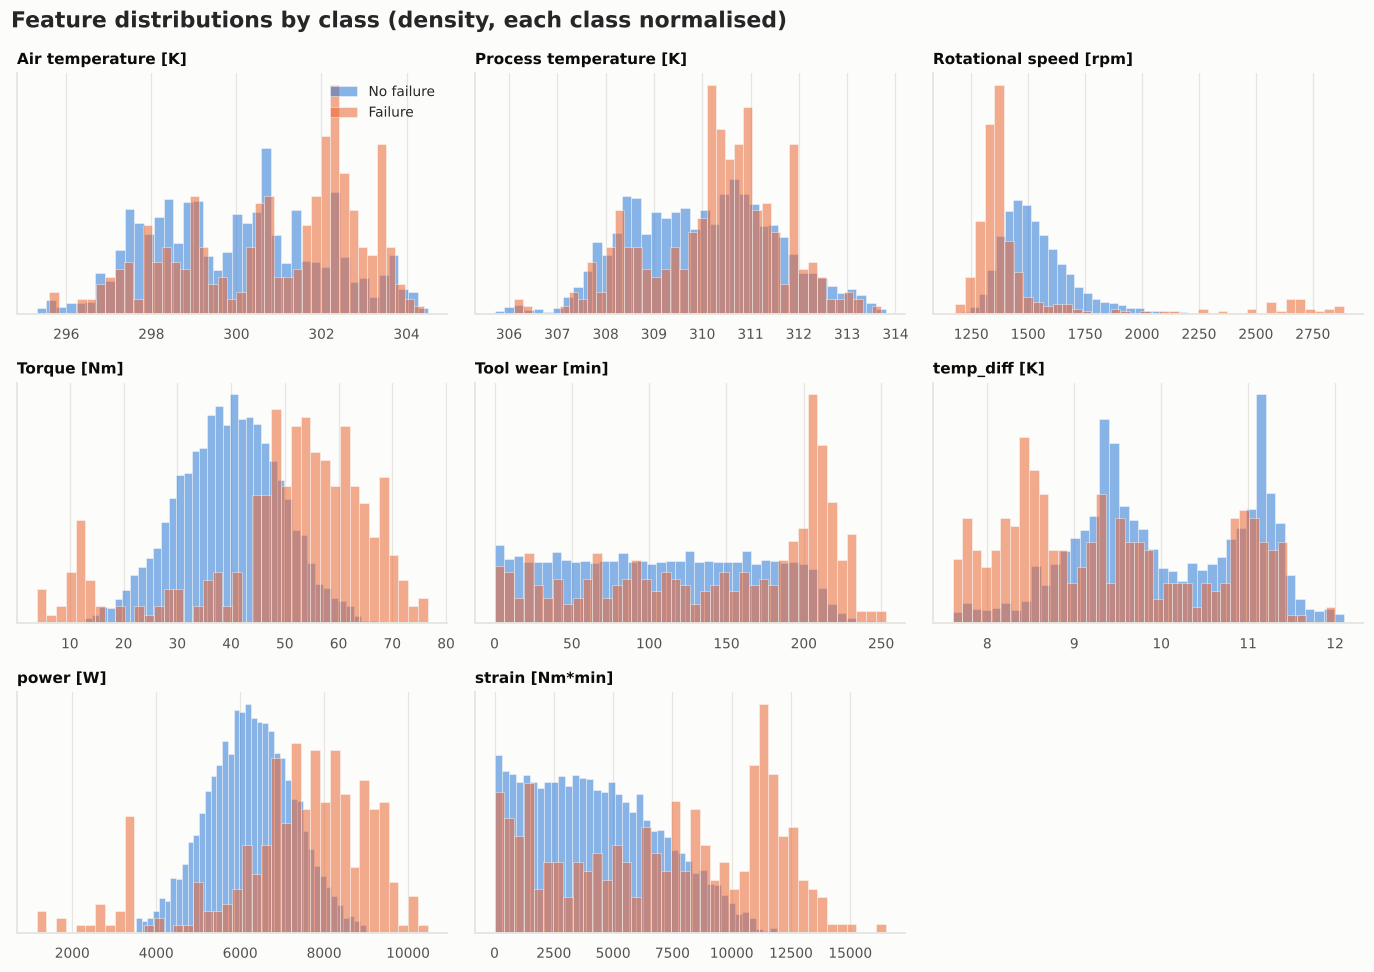

In [7]:
fe = AI4IFeatureEngineer().fit(df).transform(df)
ENG = ["temp_diff [K]", "power [W]", "strain [Nm*min]"]
cols = C.AI4I_NUMERIC + ENG
V.save(V.class_conditional_hist(fe, cols, C.AI4I_TARGET), FIGD / "03_feature_distributions.png"); plt.show()

## 7. Correlation analysis

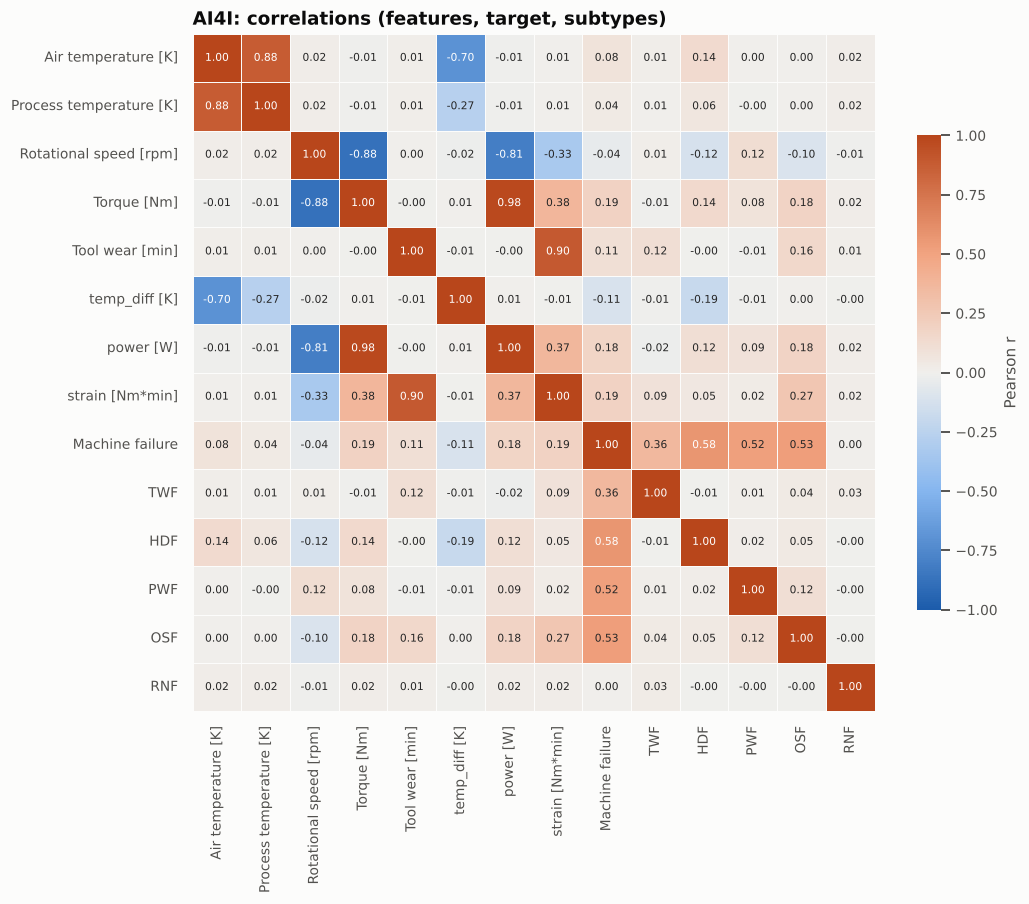

HDF                        0.576
OSF                        0.531
PWF                        0.523
TWF                        0.363
Torque [Nm]                0.191
strain [Nm*min]            0.190
power [W]                  0.176
temp_diff [K]             -0.112
Tool wear [min]            0.105
Air temperature [K]        0.083
Rotational speed [rpm]    -0.044
Process temperature [K]    0.036
RNF                        0.005


In [8]:
cm = fe[cols + [C.AI4I_TARGET] + sub]
V.save(V.correlation_heatmap(cm, "AI4I: correlations (features, target, subtypes)", figsize=(10,8)), FIGD / "04_correlation_heatmap.png"); plt.show()
print(cm.corr()[C.AI4I_TARGET].drop(C.AI4I_TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

## 8. Outlier detection (IQR rule)

,feature,outliers,share,failure_rate_in_outliers_%
0,Air temperature [K],0,0.00,NaN
1,Process temperature [K],0,0.00,NaN
2,Rotational speed [rpm],418,4.18,8.37
3,Torque [Nm],69,0.69,89.86
4,Tool wear [min],0,0.00,NaN
5,temp_diff [K],0,0.00,NaN
6,power [W],60,0.60,100.00
7,strain [Nm*min],20,0.20,100.00


overall failure rate: 3.39%


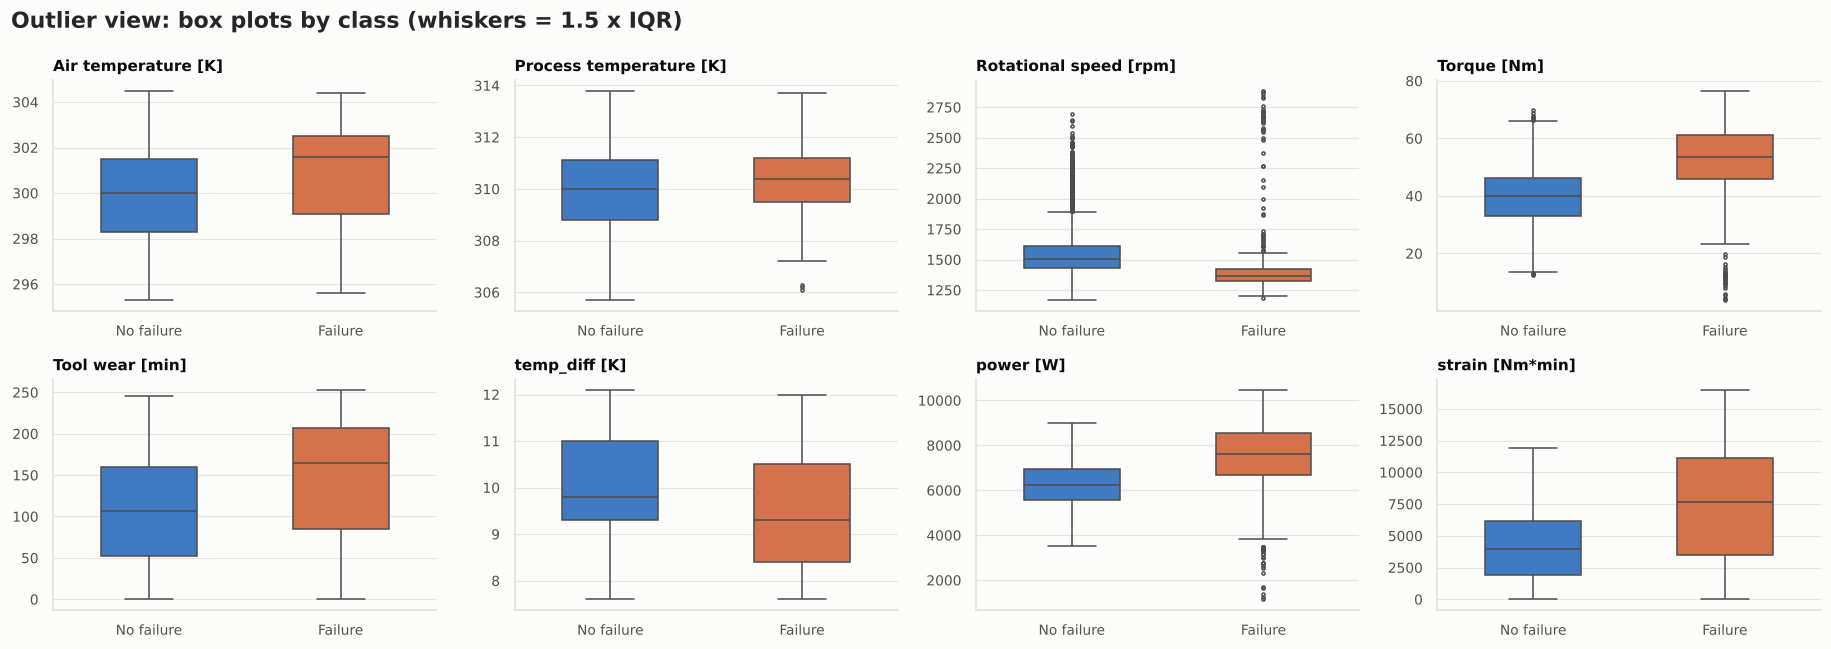

In [9]:
rows = []
for c in cols:
    q1, q3 = fe[c].quantile([.25,.75]); iqr = q3-q1
    out = (fe[c] < q1-1.5*iqr) | (fe[c] > q3+1.5*iqr)
    rows.append({"feature": c, "outliers": int(out.sum()), "share": round(out.mean()*100,2),
                 "failure_rate_in_outliers_%": round(fe.loc[out, C.AI4I_TARGET].mean()*100,2) if out.any() else np.nan})
out_df = pd.DataFrame(rows); display(out_df)
print(f"overall failure rate: {fe[C.AI4I_TARGET].mean()*100:.2f}%")
V.save(V.boxplots(fe, cols, C.AI4I_TARGET, ncols=4), FIGD / "05_outlier_boxplots.png"); plt.show()

## 9. Temperature difference investigation (heat dissipation)

,records,failure_rate,HDF_rate
temp_diff_bin,,,
"(7.0, 8.0]",249,14.86,13.25
"(8.0, 8.6]",471,18.90,17.41
"(8.6, 9.0]",1028,2.53,0.00
"(9.0, 9.5]",2160,2.36,0.00
"(9.5, 10.0]",1629,1.96,0.00
"(10.0, 10.5]",774,2.84,0.00
"(10.5, 11.0]",1547,2.33,0.00
"(11.0, 12.0]",2138,2.15,0.00
"(12.0, 13.0]",4,0.00,0.00


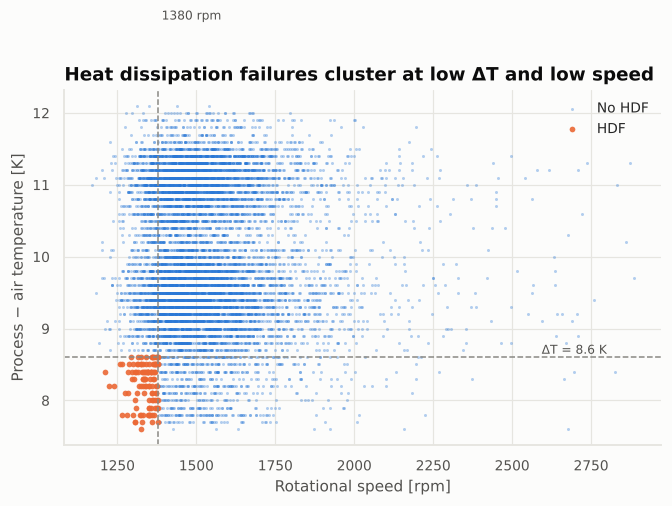

HDF rows satisfying ΔT<8.6 & rpm<1380: 115 of 115


In [10]:
fe["temp_diff_bin"] = pd.cut(fe["temp_diff [K]"], bins=[7,8,8.6,9,9.5,10,10.5,11,12,13])
t = fe.groupby("temp_diff_bin", observed=True).agg(records=(C.AI4I_TARGET,"size"), failure_rate=(C.AI4I_TARGET,"mean"), HDF_rate=("HDF","mean"))
display((t.assign(failure_rate=t.failure_rate*100, HDF_rate=t.HDF_rate*100)).round(2))
fig, ax = plt.subplots(figsize=(7,4.2))
for k,lab,col,s in [(0,"No HDF",V.SERIES[0],4),(1,"HDF",V.SERIES[1],14)]:
    d = fe[fe.HDF==k]; ax.scatter(d["Rotational speed [rpm]"], d["temp_diff [K]"], s=s, alpha=.35 if k==0 else .9, color=col, label=lab, linewidths=0)
ax.axhline(8.6, color=V.MUTED, ls="--", lw=1); ax.axvline(1380, color=V.MUTED, ls="--", lw=1)
ax.text(2800, 8.65, "ΔT = 8.6 K", fontsize=8, color=V.INK2, ha="right"); ax.text(1390, 13.3, "1380 rpm", fontsize=8, color=V.INK2)
ax.set(xlabel="Rotational speed [rpm]", ylabel="Process − air temperature [K]", title="Heat dissipation failures cluster at low ΔT and low speed"); ax.legend()
V.save(fig, FIGD / "06_temp_diff_vs_speed_hdf.png"); plt.show()
print("HDF rows satisfying ΔT<8.6 & rpm<1380:", int(((fe["temp_diff [K]"]<8.6)&(fe["Rotational speed [rpm]"]<1380)&(fe.HDF==1)).sum()), "of", int(fe.HDF.sum()))

## 10. Torque vs rotational speed (power)

corr(torque, rpm) = -0.875


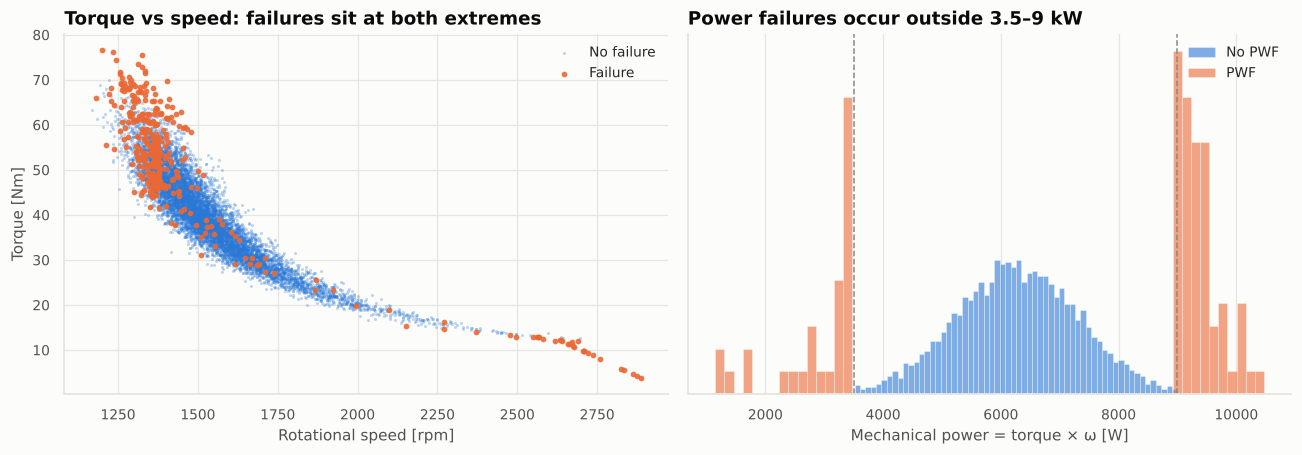

PWF rows with power <3500 or >9000 W: 95 of 95


In [11]:
print("corr(torque, rpm) =", round(fe["Torque [Nm]"].corr(fe["Rotational speed [rpm]"]),3))
fig, axes = plt.subplots(1,2, figsize=(12,4.3))
ax = axes[0]
for k,col,s,a in [(0,V.SERIES[0],4,.3),(1,V.SERIES[1],14,.9)]:
    d = fe[fe[C.AI4I_TARGET]==k]; ax.scatter(d["Rotational speed [rpm]"], d["Torque [Nm]"], s=s, alpha=a, color=col, label=V.CLASS_NAMES[k], linewidths=0)
ax.set(xlabel="Rotational speed [rpm]", ylabel="Torque [Nm]", title="Torque vs speed: failures sit at both extremes"); ax.legend()
ax = axes[1]
for k,lab,col in [(0,"No PWF",V.SERIES[0]),(1,"PWF",V.SERIES[1])]:
    ax.hist(fe.loc[fe.PWF==k,"power [W]"], bins=60, density=True, alpha=.6, color=col, label=lab, edgecolor=V.SURFACE, linewidth=.4)
for x in (3500, 9000): ax.axvline(x, color=V.MUTED, ls="--", lw=1)
ax.set(xlabel="Mechanical power = torque × ω [W]", title="Power failures occur outside 3.5–9 kW"); ax.set_yticks([]); ax.legend()
fig.tight_layout(); V.save(fig, FIGD / "07_torque_speed_power.png"); plt.show()
pw = fe["power [W]"]; print("PWF rows with power <3500 or >9000 W:", int((((pw<3500)|(pw>9000)) & (fe.PWF==1)).sum()), "of", int(fe.PWF.sum()))

## 11. Tool wear × torque (overstrain) by product type

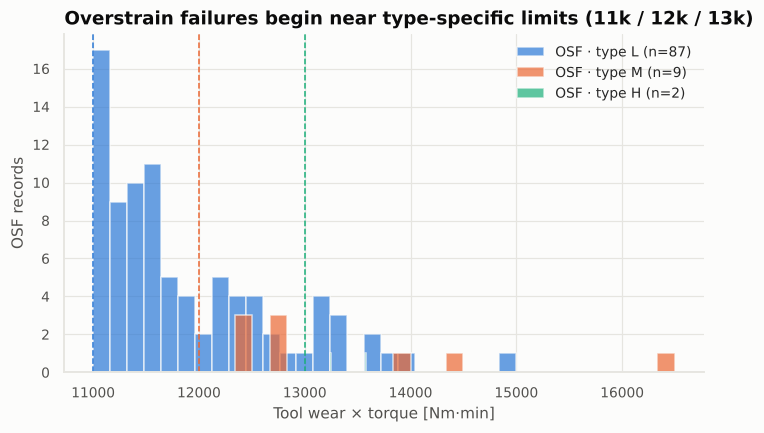

      min strain at OSF  OSF count
Type                              
L               11003.2       87.0
M               12337.2        9.0
H               13234.8        2.0


In [12]:
fig, ax = plt.subplots(figsize=(7.5,4))
for i,tp in enumerate(["L","M","H"]):
    d = fe[fe.Type==tp]
    ax.hist(d.loc[d.OSF==1,"strain [Nm*min]"], bins=25, alpha=.7, color=V.SERIES[i], label=f"OSF · type {tp} (n={int(d.OSF.sum())})", edgecolor=V.SURFACE)
for i,(tp,th) in enumerate([("L",11000),("M",12000),("H",13000)]): ax.axvline(th, color=V.SERIES[i], ls="--", lw=1)
ax.set(xlabel="Tool wear × torque [Nm·min]", ylabel="OSF records", title="Overstrain failures begin near type-specific limits (11k / 12k / 13k)"); ax.legend()
V.save(fig, FIGD / "08_overstrain_by_type.png"); plt.show()
print(fe.groupby("Type").apply(lambda d: pd.Series({"min strain at OSF": d.loc[d.OSF==1,"strain [Nm*min]"].min(), "OSF count": int(d.OSF.sum())})).loc[["L","M","H"]])

## 12. Tool wear and tool-wear failures

In [13]:
print(fe.loc[fe.TWF==1, "Tool wear [min]"].describe().round(1).to_string())
print("failure rate when tool wear >= 200 min:", f"{fe.loc[fe['Tool wear [min]']>=200, C.AI4I_TARGET].mean():.2%}", "| < 200:", f"{fe.loc[fe['Tool wear [min]']<200, C.AI4I_TARGET].mean():.2%}")

count     46.0
mean     216.4
std       12.3
min      198.0
25%      207.0
50%      214.5
75%      224.2
max      253.0
failure rate when tool wear >= 200 min: 15.36% | < 200: 2.35%


## 13. EDA summary → preprocessing decisions

- **Clean data:** 10,000 rows, no missing values, no duplicates. `UDI` and `Product ID` are
  pure identifiers → dropped.
- **Imbalance:** 339 failures (3.39%, about 28:1). Accuracy is uninformative (always predicting
  "no failure" scores 96.6%), so evaluation centers on recall, F1 and PR-AUC.
- **Leakage:** the five subtype flags *define* the target (r with the target 0.36–0.58 for TWF/HDF/PWF/OSF; RNF ≈ 0 because 18 of its 19 rows are labeled 0)
  → excluded from inputs, kept only for error analysis.
- **Label quirks:** 9 failures have no subtype; 18 of 19 RNF rows are labeled "no failure."
  The target is used as published.
- **Failure physics is recoverable from the data:** all 115 HDF rows have ΔT < 8.6 K and speed
  < 1380 rpm; all 95 PWF rows have power outside 3.5–9 kW; OSF begins at type-specific strain
  limits (11k / 12k / 13k Nm·min); TWF appears at 198–253 min tool wear. → Engineer
  **ΔT, power, strain**.
- **Torque and speed** are strongly anti-correlated (r = −0.875) by construction (constant-power
  generation), so their product (power) carries information neither has alone.
- **Outliers** in torque, power and strain are almost all failures (90–100% failure rate) →
  they are signal, not noise, so none are removed.
- **Product type:** failure rate L 3.92% > M 2.77% > H 2.09% → one-hot encoded.
- **Scaling:** standardization for LR and KNN; it has no effect on trees.